In [2]:
!pip install -q ultralytics opencv-python matplotlib pandas seaborn pillow

In [3]:
import torch
import ultralytics
import cv2
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", ultralytics.__version__)
print("OpenCV Version:", cv2.__version__)

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch Version: 2.11.0+cu130
Ultralytics Version: 8.4.194
OpenCV Version: 4.14.0
GPU Available: True
GPU Name: Tesla T4


In [4]:
import os
import cv2
import torch
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
PROJECT_DIR = "/content/YOLOv8_Object_Detection"

os.makedirs(PROJECT_DIR, exist_ok=True)

os.makedirs(f"{PROJECT_DIR}/models", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/predictions", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/graphs", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/reports", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [6]:
DATASET = "coco128.yaml"

print("Dataset:", DATASET)
print("Dataset configuration ready!")

Dataset: coco128.yaml
Dataset configuration ready!


In [7]:
model = YOLO("yolov8n.pt")

model.info()

print("YOLOv8n model loaded successfully!")

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs
YOLOv8n model loaded successfully!


In [8]:
EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 8

device = 0 if torch.cuda.is_available() else "cpu"

train_results = model.train(
    data=DATASET,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=device,
    workers=2,
    project=PROJECT_DIR,
    name="yolov8n_training",
    exist_ok=True,
    patience=10,
    seed=42,
    plots=True,
    save=True,
    verbose=True
)

print("Model training completed!")

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_training, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

In [9]:
TRAINING_DIR = Path(PROJECT_DIR) / "yolov8n_training"

BEST_MODEL = TRAINING_DIR / "weights" / "best.pt"

best_model = YOLO(str(BEST_MODEL))

print("Best model loaded successfully!")
print("Model path:", BEST_MODEL)

Best model loaded successfully!
Model path: /content/YOLOv8_Object_Detection/yolov8n_training/weights/best.pt


In [10]:
metrics = best_model.val(
    data=DATASET,
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=device,
    plots=True,
    project=PROJECT_DIR,
    name="yolov8n_evaluation",
    exist_ok=True
)

print("Model evaluation completed!")

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1754.6±738.2 MB/s, size: 58.0 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 44.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.6it/s 2.4s
                   all        128        929      0.834      0.679      0.774      0.597
                person         61        254      0.934      0.583      0.819      0.597
               bicycle          3          6       0.87      0.333      0.467      0.366
                   car         12         46      0.921      0.255      0.495      0.277
            motorcycle          4          5      0.872        0.8       0.92      0.835
              airplane          5  

In [11]:
precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

accuracy_metrics = {
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_score,
    "mAP@50": map50,
    "mAP@50-95": map50_95
}

print("MODEL PERFORMANCE")
print("-------------------------")

for name, value in accuracy_metrics.items():
    print(f"{name}: {value:.4f} ({value*100:.2f}%)")

MODEL PERFORMANCE
-------------------------
Precision: 0.8337 (83.37%)
Recall: 0.6788 (67.88%)
F1 Score: 0.7483 (74.83%)
mAP@50: 0.7745 (77.45%)
mAP@50-95: 0.5973 (59.73%)


In [12]:
RESULTS_CSV = TRAINING_DIR / "results.csv"

df = pd.read_csv(RESULTS_CSV)

df.columns = df.columns.str.strip()

print("Training history:")
display(df.head())

print("\nAvailable columns:")
print(df.columns.tolist())

Training history:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,6.90791,1.30014,1.61951,1.30125,0.68165,0.54986,0.62923,0.46630,1.08580,1.09204,1.11212,0.000037,0.000037,0.000037
1,2,10.06850,1.25162,1.53537,1.26927,0.70761,0.55331,0.63543,0.47146,1.08481,1.07769,1.10999,0.000074,0.000074,0.000074
2,3,13.17530,1.21352,1.42297,1.23980,0.72010,0.57654,0.65574,0.48422,1.08114,1.06977,1.10322,0.000109,0.000109,0.000109
3,4,16.50080,1.16558,1.36779,1.23294,0.72943,0.60087,0.67258,0.49707,1.07745,1.06216,1.09748,0.000107,0.000107,0.000107
4,5,20.44650,1.17736,1.29156,1.20171,0.75803,0.61056,0.68603,0.50984,1.07012,1.04163,1.08952,0.000103,0.000103,0.000103



Available columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


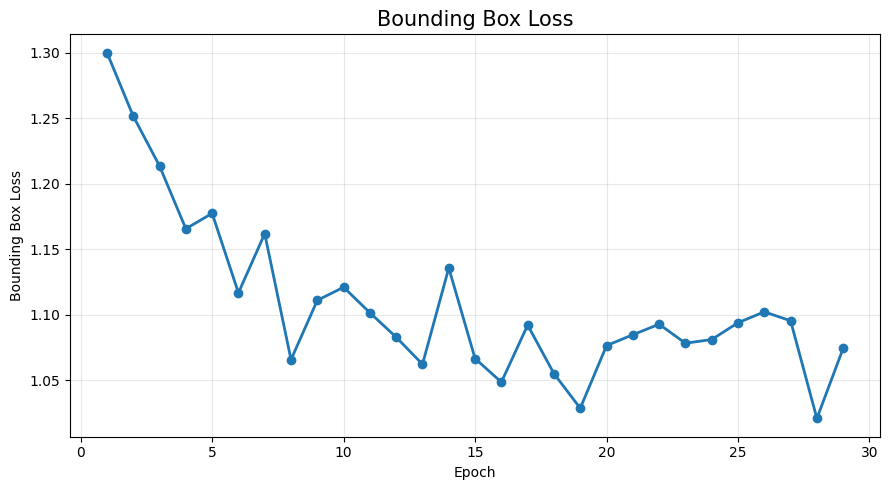

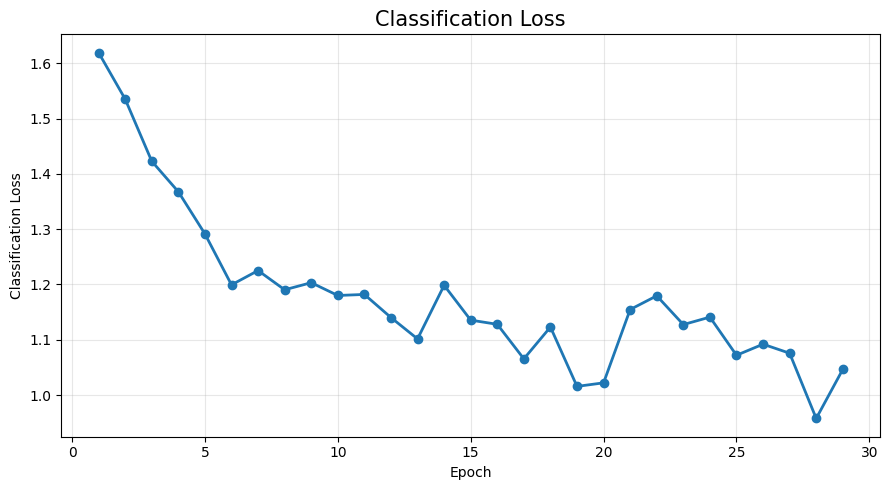

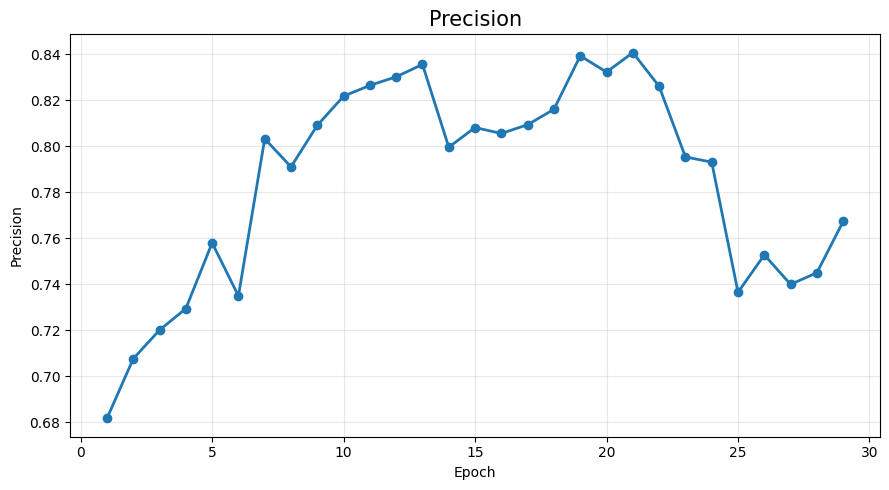

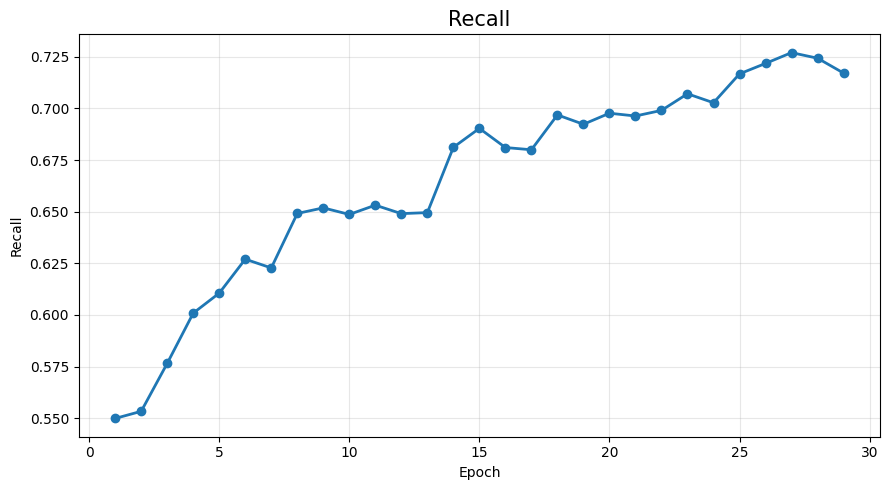

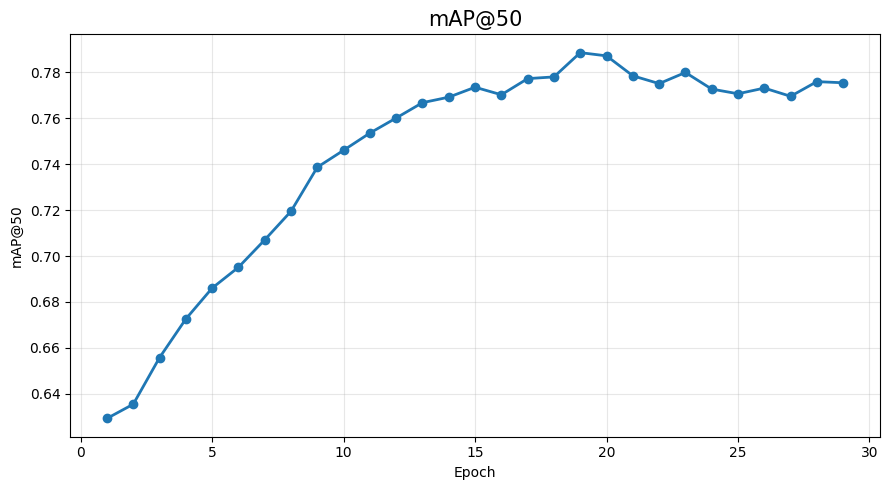

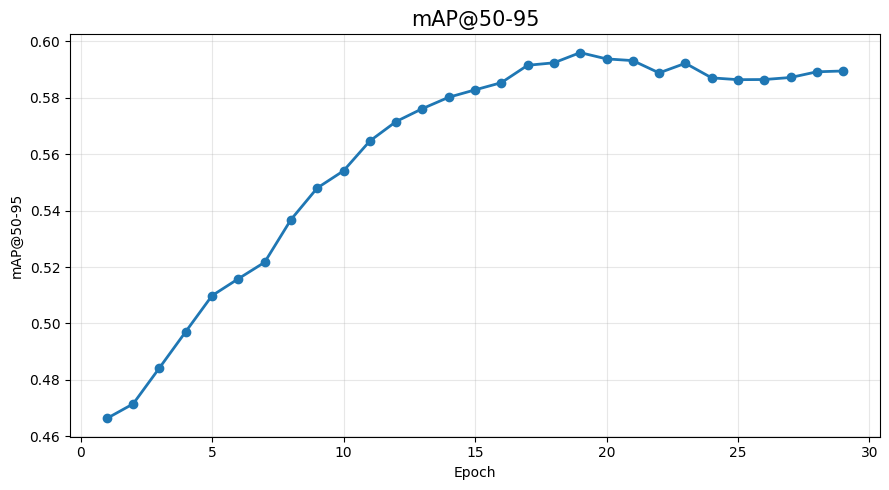

Six evaluation graphs generated!


In [13]:
graph_folder = Path(PROJECT_DIR) / "graphs"
graph_folder.mkdir(exist_ok=True)

graph_config = [
    ("train/box_loss", "Bounding Box Loss",
     "graph_1_box_loss.png"),

    ("train/cls_loss", "Classification Loss",
     "graph_2_classification_loss.png"),

    ("metrics/precision(B)", "Precision",
     "graph_3_precision.png"),

    ("metrics/recall(B)", "Recall",
     "graph_4_recall.png"),

    ("metrics/mAP50(B)", "mAP@50",
     "graph_5_map50.png"),

    ("metrics/mAP50-95(B)", "mAP@50-95",
     "graph_6_map50_95.png")
]

for column, title, filename in graph_config:

    if column not in df.columns:
        print("Missing column:", column)
        continue

    plt.figure(figsize=(9, 5))

    plt.plot(
        df["epoch"],
        df[column],
        marker="o",
        linewidth=2
    )

    plt.title(title, fontsize=15)
    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        graph_folder / filename,
        dpi=300
    )

    plt.show()
    plt.close()

print("Six evaluation graphs generated!")

In [14]:
summary_data = {
    "Evaluation Metric": [
        "Precision",
        "Recall",
        "F1 Score",
        "mAP@50",
        "mAP@50-95"
    ],

    "Score": [
        precision,
        recall,
        f1_score,
        map50,
        map50_95
    ],

    "Percentage": [
        precision * 100,
        recall * 100,
        f1_score * 100,
        map50 * 100,
        map50_95 * 100
    ]
}

summary_df = pd.DataFrame(summary_data)

display(
    summary_df.style
    .format({
        "Score": "{:.4f}",
        "Percentage": "{:.2f}%"
    })
    .set_caption("YOLOv8n Model Evaluation Summary")
)

summary_df.to_csv(
    f"{PROJECT_DIR}/reports/accuracy_metrics.csv",
    index=False
)

,Evaluation Metric,Score,Percentage
0,Precision,0.8337,83.37%
1,Recall,0.6788,67.88%
2,F1 Score,0.7483,74.83%
3,mAP@50,0.7745,77.45%
4,mAP@50-95,0.5973,59.73%


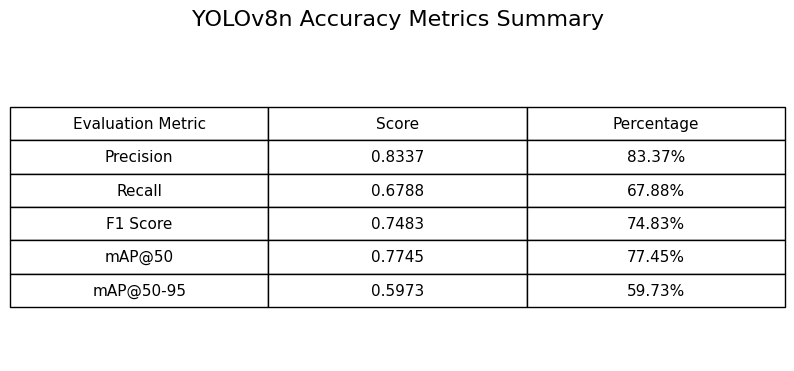

Accuracy summary image saved!


In [15]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.axis("off")

table = ax.table(
    cellText=[
        [
            row["Evaluation Metric"],
            f'{row["Score"]:.4f}',
            f'{row["Percentage"]:.2f}%'
        ]
        for _, row in summary_df.iterrows()
    ],
    colLabels=[
        "Evaluation Metric",
        "Score",
        "Percentage"
    ],
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

plt.title(
    "YOLOv8n Accuracy Metrics Summary",
    fontsize=16,
    pad=20
)

plt.savefig(
    f"{PROJECT_DIR}/reports/accuracy_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy summary image saved!")

In [18]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded image:", image_path)

Saving WhatsApp Image 2026-10-31 at 8.22.02 PM.jpeg to WhatsApp Image 2026-10-31 at 8.22.02 PM.jpeg
Uploaded image: WhatsApp Image 2026-10-31 at 8.22.02 PM.jpeg


In [19]:
CONFIDENCE_THRESHOLD = 0.35

results = best_model.predict(
    source=image_path,
    conf=CONFIDENCE_THRESHOLD,
    imgsz=640,
    save=True,
    project=PROJECT_DIR,
    name="predictions",
    exist_ok=True
)

print("Object detection completed!")


image 1/1 /content/WhatsApp Image 2026-10-31 at 8.22.02 PM.jpeg: 640x480 1 laptop, 11.8ms
Speed: 2.5ms preprocess, 11.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/YOLOv8_Object_Detection/predictions
Object detection completed!


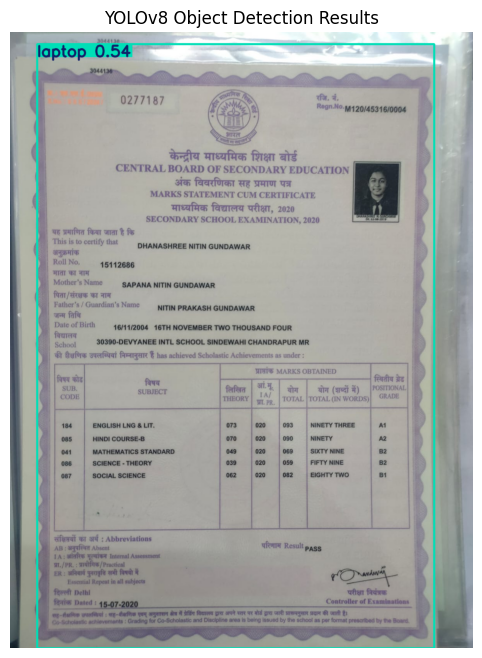


Detected objects:
Object: laptop | Confidence: 0.54


In [20]:
for result in results:

    annotated_image = result.plot()

    annotated_image = cv2.cvtColor(
        annotated_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 8))

    plt.imshow(annotated_image)
    plt.axis("off")
    plt.title("YOLOv8 Object Detection Results")

    plt.show()

    print("\nDetected objects:")

    if result.boxes is not None:

        for box in result.boxes:

            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            class_name = best_model.names[class_id]

            print(
                f"Object: {class_name} | "
                f"Confidence: {confidence:.2f}"
            )

In [21]:
shutil.copy2(
    BEST_MODEL,
    f"{PROJECT_DIR}/models/best.pt"
)

print("Best trained model saved successfully!")

Best trained model saved successfully!


In [22]:
EVAL_DIR = Path(PROJECT_DIR) / "yolov8n_evaluation"

# Copy Ultralytics evaluation plots
evaluation_graphs = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for filename in evaluation_graphs:

    source = EVAL_DIR / filename

    if source.exists():

        destination = graph_folder / filename

        shutil.copy2(source, destination)

print("Evaluation plots organized!")

Evaluation plots organized!


In [23]:
print("=" * 50)
print("YOLOv8 OBJECT DETECTION PIPELINE")
print("=" * 50)

print("Model: YOLOv8n")
print("Dataset: COCO128")
print("Epochs:", EPOCHS)
print("Image Size:", IMAGE_SIZE)
print("Device:", device)

print("\nFINAL PERFORMANCE")

for metric, value in accuracy_metrics.items():
    print(f"{metric}: {value*100:.2f}%")

print("\nProject Location:", PROJECT_DIR)
print("Training Completed Successfully!")

YOLOv8 OBJECT DETECTION PIPELINE
Model: YOLOv8n
Dataset: COCO128
Epochs: 30
Image Size: 640
Device: 0

FINAL PERFORMANCE
Precision: 83.37%
Recall: 67.88%
F1 Score: 74.83%
mAP@50: 77.45%
mAP@50-95: 59.73%

Project Location: /content/YOLOv8_Object_Detection
Training Completed Successfully!


In [24]:
import zipfile

ZIP_PATH = "/content/YOLOv8_Object_Detection_Project.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, filenames in os.walk(PROJECT_DIR):

        for filename in filenames:

            filepath = os.path.join(root, filename)

            arcname = os.path.relpath(
                filepath,
                PROJECT_DIR
            )

            zipf.write(filepath, arcname)

print("Project ZIP created successfully!")

files.download(ZIP_PATH)

Project ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>